# Transfer Learning + Fine Tuning exisiting models

In this notebook we apply transfer learning and fine tuning to existing models and compare their performance.

Used models:
- ResNet-18
- EfficientNet-B0

## Import everything in colab

The follwing cell sets up the project in a fresh Colab runtime. This clones the repository, loads the dependencies and configures settings.

In [ ]:
!git clone https://github.com/michael-duer/medical-image-classification.git
%cd medical-image-classification

Cloning into 'medical-image-classification'...
remote: Enumerating objects: 8335, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 8335 (delta 9), reused 18 (delta 5), pack-reused 8312 (from 2)
Receiving objects: 100% (8335/8335), 175.11 MiB | 14.46 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/medical-image-classification


In [ ]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
import timm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Set paths
DATA_DIR = Path('/content/medical-image-classification/data')
OUTPUT_DIR = Path('/content/medical-image-classification/output')

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Set DATA_DIR to your actual dataset folder first: {DATA_DIR}")
print('Dataset path:', DATA_DIR.resolve())

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Dataset path: /content/medical-image-classification/data


## Local setup using `uv` to install dependencies DO I NEED THIS?
On a local machine, you can instead manage dependencies with `uv sync` and select that environment as your Jupyter kernel

In [ ]:
# If uv is not already installed
!pip -q install uv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 93.0 MB/s eta 0:00:00


In [ ]:
import importlib.util
import subprocess
import sys

required = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "PIL": "pillow",
    "tqdm": "tqdm",
}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run(["uv", "pip", "install", "--python", sys.executable, *missing], check=True)
else:
    print("All baseline dependencies are already installed.")
print("Notebook Python:", sys.executable)
print("If an import fails after installation, restart the runtime and rerun.")

# Set paths to data
DATA_DIR = Path('/data')
OUTPUT_DIR = Path('/output')

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Set DATA_DIR to your actual dataset folder first: {DATA_DIR}")
print('Dataset path:', DATA_DIR.resolve())

All baseline dependencies are already installed.
Notebook Python: /usr/bin/python3
If an import fails after installation, restart the runtime and rerun.


FileNotFoundError: Set DATA_DIR to your actual dataset folder first: /data

## 1. Load and inspect data

The dataset already split the data into `train`, `test` and `eval` folders. The same label mapping and normalization will be used by every model. The number of images between classes varies a lot. To tackle this we used augmentation techniques like rotation.

In [ ]:
from torchvision.datasets.folder import default_loader
from src.data_augmentation import BalancedAugmentedDataset
from src.class_imbalance import (
    get_transforms,
    create_weighted_sampler
)

# Normalization matches common ImageNet-pretrained ResNet/EfficientNet weights.
# Keep these choices the same in all experiments.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

IMAGE_SIZE = 224
BATCH_SIZE = 16

class ImageSubset(Dataset):
    """ImageFolder-compatible subset that stores explicit (path, label) entries."""
    def __init__(self, samples, transform):
        self.samples = [(str(p), int(y)) for p, y in samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = default_loader(path)  # RGB
        return self.transform(img), label

# Load datasets
train_source = datasets.ImageFolder(DATA_DIR / 'train')
val_source = datasets.ImageFolder(DATA_DIR / 'val')
test_source = datasets.ImageFolder(DATA_DIR / 'test')

split_samples = {
        'train': train_source.samples,
        'val': val_source.samples,
        'test': test_source.samples,
    }

base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

datasets_by_split = {
    split: ImageSubset(samples, base_transform)
    for split, samples in split_samples.items()
}
loaders = {
    split: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == 'train'),
                      pin_memory=(DEVICE.type == 'cuda'))
    for split, ds in datasets_by_split.items()
}

class_names = train_source.classes
num_classes = len(class_names)

# # Apply augmentation to training data to handle class imbalance
# train_dataset = BalancedAugmentedDataset(
#     split_samples["train"],
#     image_size=IMAGE_SIZE,
#     max_rotation=5,
#     seed=SEED,
#     mean=MEAN,
#     std=STD
# )

# # Validation and test transformations (no augmentation)
# base_transform = transforms.Compose([
#     transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
#     transforms.ToTensor(),
#     transforms.Normalize(MEAN, STD)
# ])

# # Validation and test datasets: unchanged
# val_dataset = ImageSubset(
#     split_samples["val"],
#     base_transform
# )

# test_dataset = ImageSubset(
#     split_samples["test"],
#     base_transform
# )

# datasets_by_split = {
#     "train": train_dataset,
#     "val": val_dataset,
#     "test": test_dataset
# }

# loaders = {
#     split: DataLoader(
#         ds,
#         batch_size=BATCH_SIZE,
#         shuffle=(split == "train"),
#         pin_memory=(DEVICE.type == "cuda")
#     )
#     for split, ds in datasets_by_split.items()
# }

# images, labels = next(iter(loaders["train"]))
# print("One batch:", images.shape)


In [ ]:

import numpy as np
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision.datasets.folder import default_loader
from torchvision import transforms

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 5

class ImageSubset(Dataset):
    """ImageFolder-compatible subset that stores explicit (path, label) entries."""
    def __init__(self, samples, transform):
        self.samples = [(str(p), int(y)) for p, y in samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = default_loader(path)  # RGB
        return self.transform(img), label

# Load datasets
train_source = datasets.ImageFolder(DATA_DIR / 'train')
val_source = datasets.ImageFolder(DATA_DIR / 'val')
test_source = datasets.ImageFolder(DATA_DIR / 'test')

split_samples = {
        'train': train_source.samples,
        'val': val_source.samples,
        'test': test_source.samples,
    }

# Mild augmentation for knee X-rays
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.05,
        contrast=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# No random augmentation for validation/test
base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_dataset = ImageSubset(
    split_samples["train"],
    train_transform
)

val_dataset = ImageSubset(
    split_samples["val"],
    base_transform
)

test_dataset = ImageSubset(
    split_samples["test"],
    base_transform
)

# Build weighted sampler from original training labels
labels = np.array([
    label for _, label in split_samples["train"]
])

counts = np.bincount(labels, minlength=NUM_CLASSES)

# Softer balancing than 1/count
alpha = 1
class_weights = 1.0 / (counts ** alpha)
sample_weights = class_weights[labels]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(labels),
    replacement=True
)

datasets_by_split = {
    "train": train_dataset,
    "val": val_dataset,
    "test": test_dataset
}

loaders = {
    "train": DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        pin_memory=(DEVICE.type == "cuda")
    ),
    "val": DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda")
    ),
    "test": DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda")
    )
}

print("Original class counts:", counts)
print("Class sampling weights:", class_weights)
print("Training batches:", len(loaders["train"]))


Original class counts: [2286 1046 1516  757  173]
Class sampling weights: [0.00043745 0.00095602 0.00065963 0.001321   0.00578035]
Training batches: 362


## 2. Transfer learning & Fine Tuning to ResNet-18
Then optionally unfreeze the last residual block (layer4) and the classifier, using smaller learning rates.


### 2.1 Set Training parameters
Specify learning rate, loss function and number of training loops (epochs). Also specify the number of classes to predict as we will replace the last layer of the following models with a classifier suitable for our task.

In [ ]:
LEARNING_RATE = 1e-3
NUM_EPOCHS = 10
NUM_CLASSES = 5
criterion = nn.CrossEntropyLoss()

Function to run training loop:

In [ ]:
def run_epoch(model, loader, optimizer=None, epoch=None, num_epochs=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, correct, count = 0.0, 0, 0

    phase = "Train" if is_training else "Validate"
    description = f"Epoch [{epoch}/{num_epochs}] | {phase}"

    with tqdm(loader, leave=False, desc=description) as progressbar:
      for x, y in progressbar:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(x)
            loss = criterion(logits, y)

            if is_training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)

        progressbar.set_postfix(
            loss=f"{total_loss / count:.4f}",
            acc=f"{correct / count:.2%}"
        )

    return {'loss': total_loss / count, 'accuracy': correct / count}

### 2.2 Resnet18
Load model  (**link einfügen**) using the timm package. Replace the last fully connected (original) layer of the model with a new one for our 5 classes. In a first step we only tain the classifier and keep all other layers frozen.

In [ ]:
# Create pretrained ResNet18 with 5 output classes
resnet18 = timm.create_model(
    'resnet18',
    pretrained=True,
    num_classes=NUM_CLASSES
    )

# Freeze pretrained backbone
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze classification head
for param in resnet18.fc.parameters():
    param.requires_grad = True

# Move the model to gpu
resnet18 = resnet18.to(DEVICE)

# Only optimize classifier parameters
optimizer = torch.optim.AdamW(
    resnet18.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

## 2.2.1 Training + validation loops

Epoch [1/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 1.4275 | Train Acc: 37.85% | Val Loss: 1.3814 | Val Acc: 39.71%


Epoch [2/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [2/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

...

Epoch [9/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 1.2410 | Train Acc: 46.63% | Val Loss: 1.2762 | Val Acc: 44.55%


Epoch [10/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [10/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 1.2303 | Train Acc: 46.97% | Val Loss: 1.2670 | Val Acc: 43.95%


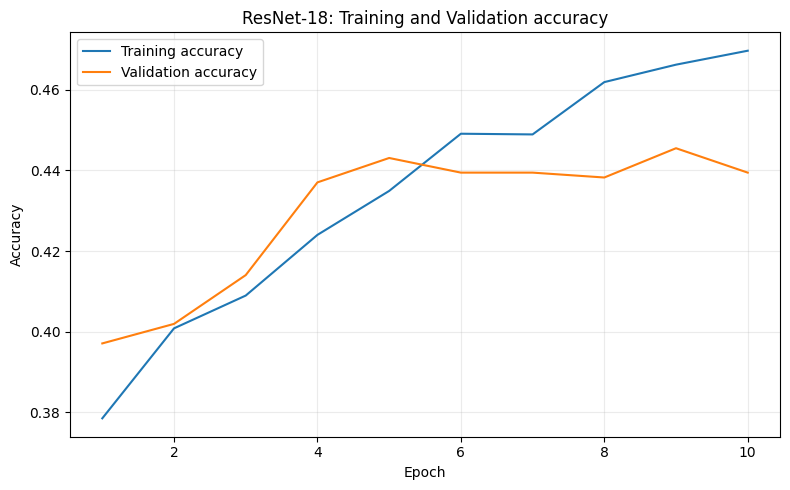

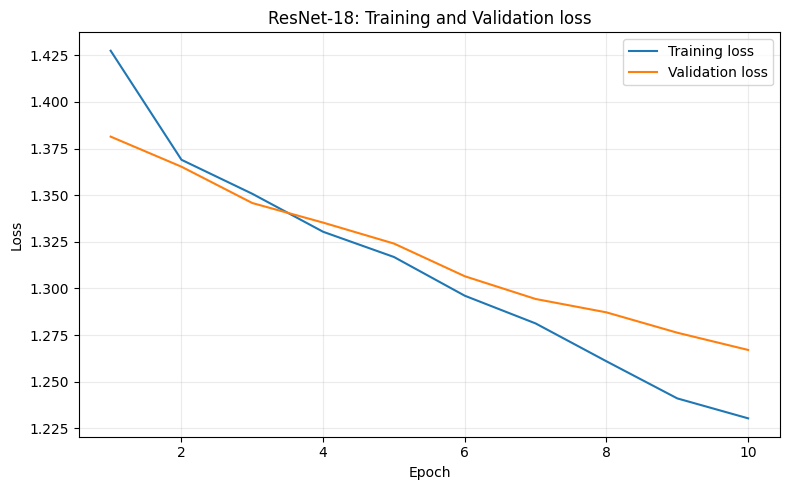

{}

In [ ]:
history_resnet18 = []
best_val_loss = float("inf")
# Stops model after 4 epochs of not improving validation loss
early_stop_rate = 4
epochs_without_improvement = 0
# Reduce learning rates when validation loss stagnates
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

for epoch in range(1, NUM_EPOCHS + 1):
    train_stats = run_epoch(
        resnet18, loaders['train'], optimizer,
        epoch=epoch, num_epochs=NUM_EPOCHS
    )

    val_stats = run_epoch(
        resnet18, loaders['val'],
        epoch=epoch, num_epochs=NUM_EPOCHS
    )

    history_resnet18.append({
      'epoch': epoch,
      'train_loss': train_stats['loss'],
      'train_accuracy': train_stats['accuracy'],
      'val_loss': val_stats['loss'],
      'val_accuracy': val_stats['accuracy']
    })

    tqdm.write(
      f"Epoch [{epoch}/{NUM_EPOCHS}] | "
      f"Train Loss: {train_stats['loss']:.4f} | "
      f"Train Acc: {train_stats['accuracy']:.2%} | "
      f"Val Loss: {val_stats['loss']:.4f} | "
      f"Val Acc: {val_stats['accuracy']:.2%}"
    )

    scheduler.step(val_stats['loss'])

    # Stop training if validation loss does not improve
    if val_stats['loss'] < best_val_loss:
        best_val_loss = val_stats['loss']
        epochs_without_improvement = 0
        # Save best model
        torch.save(resnet18.state_dict(), "best_resnet18_stage1.pth")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stop_rate:
        print("Early stopping triggered!")
        break

# Plot training metrics over epochs
from src.metrics import plot_training_history
plot_training_history(
    history_resnet18,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="ResNet-18",
    show_plots = True,
    save_plots = False
)

After training the classification layer we unfreeze layer4 as well and continue training the mode.

In [ ]:
# Restore best model from Stage 1
resnet18.load_state_dict(
    torch.load(
        "best_resnet18_stage1.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

# Freeze all layers
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze layer4 (layer before classifier)
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True

# Set optimizer with different learning rates
optimizer = torch.optim.AdamW(
    [
        {
            "params": resnet18.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": resnet18.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

# New scheduler for Stage 2
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

Train again

In [ ]:
history_resnet18 = []
best_val_loss = float("inf")
# Stops model after 4 epochs of not improving validation loss
early_stop_rate = 4
epochs_without_improvement = 0
# Reduce learning rates when validation loss stagnates
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

for epoch in range(1, NUM_EPOCHS + 1):
    train_stats = run_epoch(
        resnet18, loaders['train'], optimizer,
        epoch=epoch, num_epochs=NUM_EPOCHS
    )

    val_stats = run_epoch(
        resnet18, loaders['val'],
        epoch=epoch, num_epochs=NUM_EPOCHS
    )

    history_resnet18.append({
      'epoch': epoch,
      'train_loss': train_stats['loss'],
      'train_accuracy': train_stats['accuracy'],
      'val_loss': val_stats['loss'],
      'val_accuracy': val_stats['accuracy']
    })

    tqdm.write(
      f"Epoch [{epoch}/{NUM_EPOCHS}] | "
      f"Train Loss: {train_stats['loss']:.4f} | "
      f"Train Acc: {train_stats['accuracy']:.2%} | "
      f"Val Loss: {val_stats['loss']:.4f} | "
      f"Val Acc: {val_stats['accuracy']:.2%}"
    )

    scheduler.step(val_stats['loss'])

    # Stop training if validation loss does not improve
    if val_stats['loss'] < best_val_loss:
        best_val_loss = val_stats['loss']
        epochs_without_improvement = 0
        # Save best model
        torch.save(resnet18.state_dict(), "best_resnet18_stage2.pth")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stop_rate:
        print("Early stopping triggered!")
        break

# Plot training metrics over epochs
from src.metrics import plot_training_history
plot_training_history(
    history_resnet18,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="ResNet-18",
    show_plots = True,
    save_plots = False
)

## 4.1.2 Validation predictions and metrics

For multiclass AUROC, use softmax probabilities and specify **one-vs-rest, macro average**. If validation contains no samples for a class, AUROC may be undefined; the function reports that rather than inventing a score.

**Do not evaluate the test split yet.** The shared team should agree on the final evaluation protocol first.

In [ ]:
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    actual, probs = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        actual.append(y.numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(actual), np.concatenate(probs)

def summarize_metrics(y_true, probabilities, class_names):
    predictions = probabilities.argmax(axis=1)
    results = {'accuracy': accuracy_score(y_true, predictions)}
    present = np.unique(y_true)
    if len(class_names) == 2 and len(present) == 2:
        results['auroc'] = roc_auc_score(y_true, probabilities[:, 1])
    elif len(present) == len(class_names):
        results['auroc'] = roc_auc_score(
            y_true, probabilities, labels=np.arange(len(class_names)),
            multi_class='ovr', average='macro')
    else:
        results['auroc'] = float('nan')
        print('AUROC undefined: not all classes appear in this validation split.')
    return results, confusion_matrix(y_true, predictions,
                                      labels=np.arange(len(class_names)))

y_val, val_prob = get_predictions(model_resnet18, loaders['val'])
class_names = train_source.classes
metrics, cm = summarize_metrics(y_val, val_prob, class_names)
print('Validation metrics:', metrics)
print('Confusion matrix (rows=true, cols=predicted):')
display(pd.DataFrame(cm, index=class_names, columns=class_names))

Validation metrics: {'accuracy': 0.5375302663438256, 'auroc': np.float64(0.8324173884839053)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,166,79,78,5,0
1,27,48,70,8,0
2,16,36,136,23,1
3,1,3,24,72,6
4,0,0,0,5,22


### 4.2 Fine Tune EfficientNet-B0
Here we also replace the last fully connected (original) layer of the model with a new one for our 5 classes. All the other layers will remain "frozen".

In [ ]:
# Define the model
efficientnet_b0 = timm.create_model('efficientnet_b0', pretrained=True)
efficientnet_b0.fc = nn.Linear(efficientnet_b0.fc.in_features, NUM_CLASSES)
optimizer = torch.optim.Adam(efficientnet_b0.parameters(), lr=LEARNING_RATE)
# Move the model to gpu
efficientnet_b0 = efficientnet_b0.to(DEVICE)

## 2.3.1 Training + validation loops

In [ ]:
history_efficientnet_b0 = []

for epoch in range(1, NUM_EPOCHS + 1):
    train_stats = run_epoch(
        efficientnet_b0, loaders['train'], optimizer,
        epoch=epoch, num_epochs=NUM_EPOCHS
    )

    val_stats = run_epoch(
        efficientnet_b0, loaders['val'],
        epoch=epoch, num_epochs=NUM_EPOCHS
    )

    history_efficientnet_b0.append({
      'epoch': epoch,
      'train_loss': train_stats['loss'],
      'train_accuracy': train_stats['accuracy'],
      'val_loss': val_stats['loss'],
      'val_accuracy': val_stats['accuracy']
    })

    tqdm.write(
      f"Epoch [{epoch}/{NUM_EPOCHS}] | "
      f"Train Loss: {train_stats['loss']:.4f} | "
      f"Train Acc: {train_stats['accuracy']:.2%} | "
      f"Val Loss: {val_stats['loss']:.4f} | "
      f"Val Acc: {val_stats['accuracy']:.2%}"
    )

# Plot training metrics over epochs
from src.metrics import plot_training_history
plot_training_history(
    history_efficientnet_b0,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="EfficientNet-B0",
    show_plots = True,
    save_plots = False
)

In [ ]:
# Save the trained model
torch.save(efficientnet_b0.state_dict(), 'efficientnet_b0.pth')

## **7**. Detailed CNN evaluation

Current backend: module://matplotlib_inline.backend_inline
True labels: (1656,)
Predicted probabilities: (1656, 5)


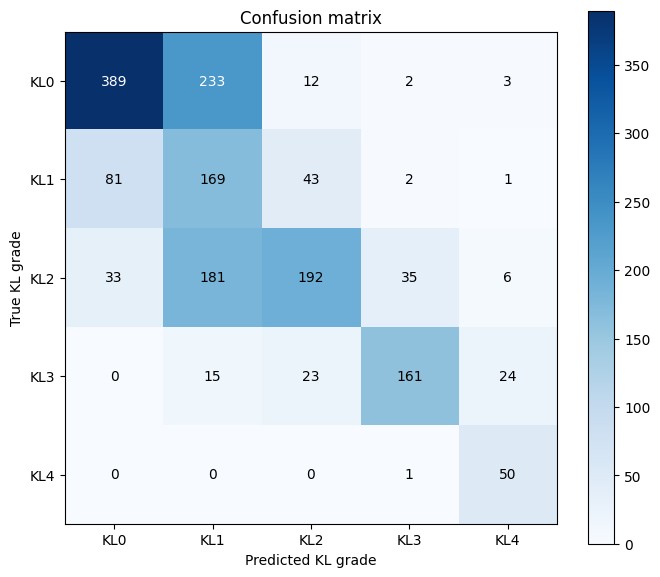

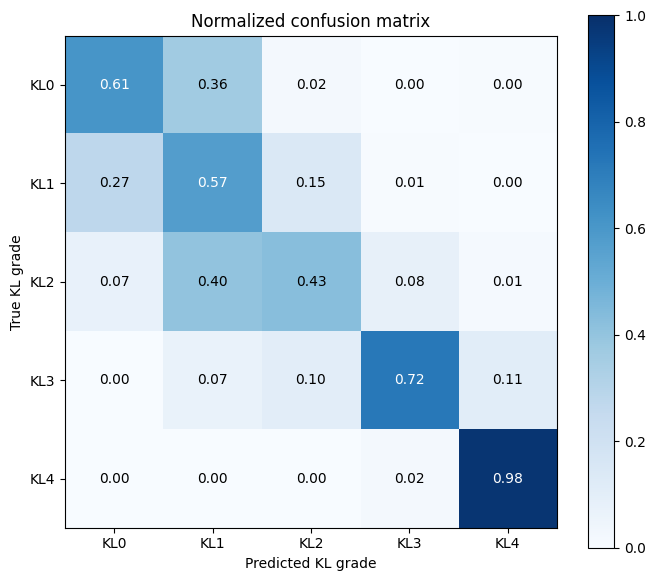

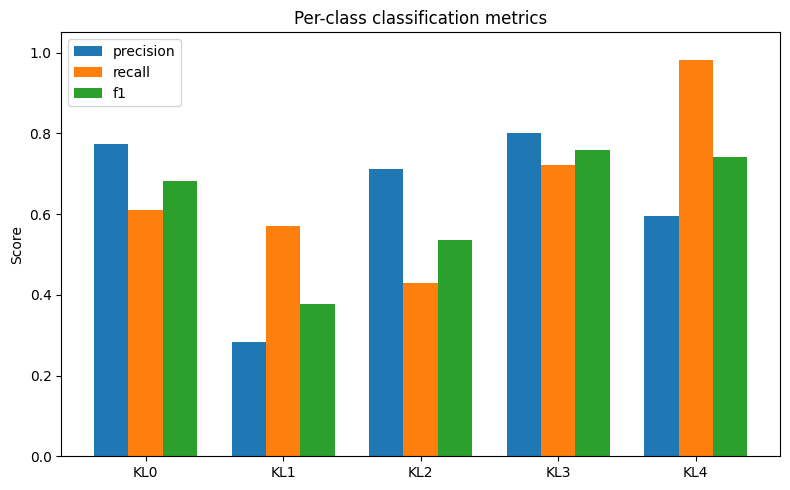

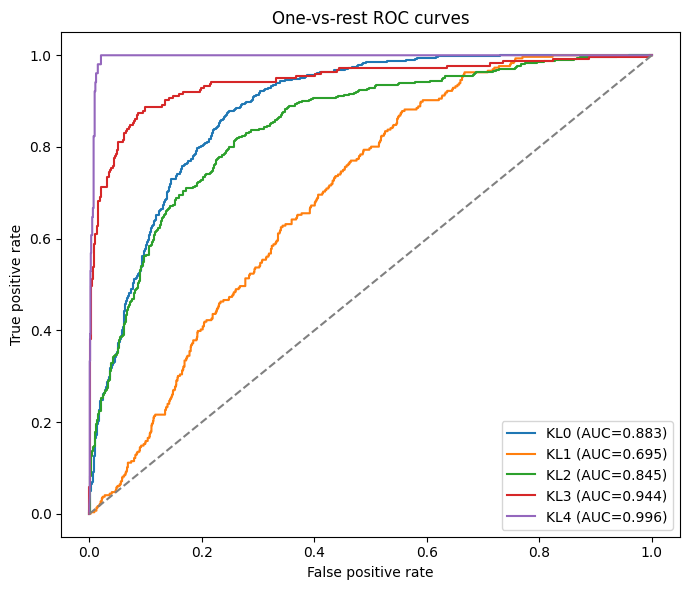

{'model_name': 'ResNet-18', 'n_samples': 1656, 'accuracy': 0.5803140096618358, 'balanced_accuracy': 0.6623210183184225, 'macro_f1': 0.619015312982096, 'weighted_f1': 0.6000998186908518, 'quadratic_weighted_kappa': 0.7878616160602909, 'mae': 0.46980676328502413, 'macro_auroc_ovr': 0.8727279843923114}


In [ ]:
import matplotlib
import matplotlib.pyplot as plt

plt.switch_backend("module://matplotlib_inline.backend_inline")

print("Current backend:", matplotlib.get_backend())

# Generate predictions
y_test, test_prob = get_predictions(efficientnet_b0, loaders["test"])

print("True labels:", y_test.shape)
print("Predicted probabilities:", test_prob.shape)

from src.metrics import evaluate_predictions

# Evaluate CNN performance
results = evaluate_predictions(
    y_true=y_test,
    y_prob=test_prob,
    model_name="Efficientnet-B0",
    show_plots=True,
    save_plots=False
)

print(results)

## 9. Optional: save a checkpoint

In Colab, **first mount Drive and set `OUTPUT_DIR` to your own writable Drive path**. Saving directly under `/content/` is temporary. Store large weights in Drive, not GitHub. Experiment settings belong alongside checkpoints.

In [ ]:
SAVE_CHECKPOINT = False  # Change to True once OUTPUT_DIR is configured.
if SAVE_CHECKPOINT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    checkpoint_file = OUTPUT_DIR / 'tiny_cnn_smoke_test.pt'
    torch.save({
        'model_state_dict': model.state_dict(),
        'class_names': class_names,
        'image_size': IMAGE_SIZE,
        'normalization_mean': MEAN,
        'normalization_std': STD,
        'seed': SEED,
        'history': history,
    }, checkpoint_file)
    print('Saved:', checkpoint_file)
else:
    print('Checkpoint not saved; set SAVE_CHECKPOINT=True to enable.')